# Phase 6 – Tata Electronics: Dholera fab analytics

This notebook supports Section 8 of the report. It has four parts:

- **A. Peer foundries:** what mature-node foundries earn per wafer, how capital-heavy they are, and the rough utilisation at which their gross margin hits zero.
- **B. Dholera ramp (Monte Carlo):** wafers out and an *illustrative output value at benchmark prices* for 2028–2032. This is **not** a Tata revenue forecast: Tata does not disclose fab economics, and the prices are peer averages.
- **C. Demand fit:** how Dholera's output compares with the part of India's chip market it could serve.
- **D. Outputs:** CSVs for the Excel "Financial scenarios" tab and the charts.

Only pandas, numpy and matplotlib are used. Every input comes from `data/` with a source column.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

## A. Peer foundries (2019–2025)

**Data:** `foundry_peers.csv`, covering six mature-node foundries: UMC, GlobalFoundries, PSMC (Tata's partner), VIS, SMIC and Hua Hong.

- Revenue, gross margin and capex come from the Bigdata.com tearsheets (FY2021–25) or, where available, the companies' own releases. When the two differ, I use the company figure.
- Utilisation and wafer shipments come from the filings. Gaps are left blank: 2019–20 is outside the tearsheet range, and GF does not publish utilisation.
- Taiwanese companies report in NT$. I convert to US$ only for 2024–25, using the rate implied by PSMC's own US$ and NT$ revenue (NT$32.07 in 2024 and NT$31.11 in 2025).

**Converting wafer sizes:** an 8-inch wafer has (200/300)² = 1/2.25 the area of a 12-inch wafer, so 12-inch equivalent = 8-inch ÷ 2.25 (SMIC's own rule).

In [2]:
peers = pd.read_csv('../data/foundry_peers.csv')
peers['ship_12in_k'] = np.where(peers['shipment_unit'].str.startswith('8-inch', na=False),
                                peers['shipments_k'] / 2.25, peers['shipments_k'])
peers['rev_per_wafer_usd'] = (peers['revenue_usd_m'] * 1e6 / (peers['ship_12in_k'] * 1e3)).round(0)
peers['capex_intensity_pct'] = (100 * peers['capex_local_m'] / peers['revenue_local_m']).round(1)

have = peers.dropna(subset=['revenue_local_m'])
print('Rows with financials:', len(have), '| rows with utilisation:', peers['utilisation_pct'].notna().sum(),
      '| rows with revenue per wafer:', peers['rev_per_wafer_usd'].notna().sum())
have[['company', 'year', 'gross_margin_pct', 'capex_intensity_pct', 'utilisation_pct', 'ship_12in_k', 'rev_per_wafer_usd']]

Rows with financials: 30 | rows with utilisation: 13 | rows with revenue per wafer: 14


,company,year,gross_margin_pct,capex_intensity_pct,utilisation_pct,ship_12in_k,rev_per_wafer_usd
2,UMC,2021,33.8,23.5,104.40,NaN,NaN
3,UMC,2022,45.1,29.7,100.60,NaN,NaN
4,UMC,2023,34.9,42.3,68.50,NaN,NaN
5,UMC,2024,32.6,39.3,NaN,NaN,NaN
6,UMC,2025,29.0,20.1,75.00,3871.000000,1973.0
9,GlobalFoundries,2021,15.3,26.9,NaN,NaN,NaN
10,GlobalFoundries,2022,27.6,37.7,NaN,2472.000000,3280.0
11,GlobalFoundries,2023,28.4,24.4,NaN,2211.000000,3343.0
12,GlobalFoundries,2024,24.5,9.3,NaN,2124.000000,3178.0
13,GlobalFoundries,2025,24.9,10.6,NaN,2345.000000,2896.0


### Revenue per wafer and capex intensity

In [3]:
rpw = peers.dropna(subset=['rev_per_wafer_usd'])
print('Revenue per 12-inch-eq wafer (US$), all peer-years:')
print(rpw.set_index(['company', 'year'])['rev_per_wafer_usd'].astype(int).to_string())
P_MIN, P_MED, P_MAX = rpw['rev_per_wafer_usd'].min(), rpw['rev_per_wafer_usd'].median(), rpw['rev_per_wafer_usd'].max()
print(f'\nMin {P_MIN:.0f} | median {P_MED:.0f} | max {P_MAX:.0f}')

ci = have.pivot(index='year', columns='company', values='capex_intensity_pct')
print('\nCapex as % of revenue:')
print(ci.to_string())
print('\nMedian capex intensity, all peer-years:', have['capex_intensity_pct'].median(), '%')

Revenue per 12-inch-eq wafer (US$), all peer-years:
company          year
UMC              2025    1973
GlobalFoundries  2022    3280
                 2023    3343
                 2024    3178
                 2025    2896
VIS              2025    1388
SMIC             2021    1815
                 2022    2305
                 2023    2425
                 2024    2253
                 2025    2164
HuaHong          2023    1254
                 2024     992
                 2025    1004

Min 992 | median 2208 | max 3343

Capex as % of revenue:
company  GlobalFoundries  HuaHong   PSMC   SMIC   UMC    VIS
year                                                        
2021                26.9     57.6   15.5   79.7  23.5   30.3
2022                37.7     40.2   25.6   86.1  29.7   36.5
2023                24.4     39.7  109.1  120.7  42.3   18.0
2024                 9.3    138.7   52.5   95.5  39.3   36.2
2025                10.6     74.9   18.4   89.5  20.1  130.2

Median capex intensi

**Reading this:** a mature-node foundry earns roughly US$1,000–3,300 per 12-inch-equivalent wafer.

- **The low end:** Hua Hong, which sells mostly power devices and specialty parts in China.
- **The high end:** GlobalFoundries, which has specialty technologies and includes some non-wafer revenue.
- **The middle:** UMC and SMIC, the closest matches to Dholera's 28–110 nm mix, sit around US$2,000–2,400.

These peers spend a fifth to two-fifths of revenue on capex. Spending rises when they are building a new fab (UMC 2023, VIS 2025, PSMC 2023).

**Correction to Phase 2:** Phase 2 assumed US$3,000 per wafer for Dholera, "anchored below UMC's ~US$4,300". The filings show UMC's actual figure was about US$1,970 in 2025. So Phase 2's fab output value was about 1.4–1.5× too high. This is carried into Phase 7.

### Utilisation vs gross margin: the rough break-even

A foundry's costs are mostly fixed: depreciation, maintenance, indirect labour and utilities. UMC says 63.9% of its manufacturing cost was fixed in 2023 (66–68% in 2021–22; 20-F FY2023). So when utilisation falls, gross margin should fall fast.

**Step 1. Pooled fit.** I fit one straight line, gross margin = a + b × utilisation (`numpy.polyfit`), through all 13 peer-years that have both numbers.

In [4]:
fit = peers.dropna(subset=['utilisation_pct', 'gross_margin_pct'])
b, a = np.polyfit(fit['utilisation_pct'], fit['gross_margin_pct'], 1)
r = np.corrcoef(fit['utilisation_pct'], fit['gross_margin_pct'])[0, 1]
print(f'Pooled fit on {len(fit)} points: GM% = {a:.1f} + {b:.3f} x utilisation%   (r = {r:.2f})')
print('-> almost flat: across companies, utilisation alone does not explain gross margin.')
fit[['company', 'year', 'utilisation_pct', 'gross_margin_pct', 'utilisation_type']]

Pooled fit on 13 points: GM% = 15.5 + 0.100 x utilisation%   (r = 0.10)
-> almost flat: across companies, utilisation alone does not explain gross margin.


,company,year,utilisation_pct,gross_margin_pct,utilisation_type
2,UMC,2021,104.40,33.8,Reported (annual average)
3,UMC,2022,100.60,45.1,Reported (annual average)
4,UMC,2023,68.50,34.9,Reported (annual average)
6,UMC,2025,75.00,29.0,Derived (annual shipments / annual capacity)
20,PSMC,2025,76.75,-3.3,Derived (9M 75% and 4Q 82%; equal quarterly ca...
27,VIS,2025,74.00,28.1,Reported (annual)
30,SMIC,2021,99.70,30.8,Derived (average of quarterly 98.7/100.4/100.3...
31,SMIC,2022,92.00,38.0,Reported (annual)
32,SMIC,2023,75.00,19.3,Reported (annualised)
33,SMIC,2024,85.50,18.0,Derived (2025 AR: +8 pp to 93.5%)


**Why the pooled line is flat:** each company has a different price level and a different depreciation load.

- **Hua Hong** ran above 100% in 2024–25 but earned only 10–12%, because its new Wuxi 12-inch fab is still being depreciated.
- **UMC** earned 35% at 68.5% utilisation in 2023, because its fabs are older and its prices held.

So "break-even utilisation" is company-specific. I estimate it in two simple ways instead.

**Step 2a. Fixed-cost method** (each peer, 2025). Take reported utilisation U₀ and gross margin g₀. Per ₹1 of revenue, cost of sales is (1 − g₀). Of that, a share f is fixed and the rest moves with volume. If prices stay the same and only volume changes, gross margin is zero when:

  U_be = U₀ × f(1 − g₀) / [1 − (1 − f)(1 − g₀)]

I use f = 63.9% (UMC, the only peer that discloses it) for every company.

**Step 2b. Within-company fit** (PSMC). PSMC's quarters 4Q24 → 4Q25 come before the 2026 price rises, so price and depreciation were roughly steady. I fit a line through those three quarters and find where it crosses zero.

In [5]:
F_FIXED = 0.639
be = fit[fit['year'] == 2025][['company', 'utilisation_pct', 'gross_margin_pct']].copy()
g0 = be['gross_margin_pct'] / 100
be['breakeven_util_%'] = (be['utilisation_pct'] * F_FIXED * (1 - g0) / (1 - (1 - F_FIXED) * (1 - g0))).round(0)
print(be.to_string(index=False))
BE_MED = be['breakeven_util_%'].median()
print(f'\nMedian peer break-even (fixed-cost method): {BE_MED:.0f}%')

pq = pd.read_csv('../data/psmc_quarterly.csv')
pfit = pq[pq['quarter'].isin(['4Q24', '3Q25', '4Q25'])]
pb, pa = np.polyfit(pfit['utilisation_pct'], pfit['gross_margin_pct'], 1)
BE_NEW = -pa / pb
print(f'PSMC quarterly fit (4Q24-4Q25): GM% = {pa:.1f} + {pb:.2f} x util%  -> GM = 0 at {BE_NEW:.0f}% utilisation')
print(f'Each +10 pp utilisation -> about +{10*pb:.0f} pp gross margin at PSMC')

company  utilisation_pct  gross_margin_pct  breakeven_util_%
    UMC            75.00              29.0              46.0
   PSMC            76.75              -3.3              81.0
    VIS            74.00              28.1              46.0
   SMIC            93.50              21.0              66.0
HuaHong           106.10              11.8              88.0

Median peer break-even (fixed-cost method): 66%
PSMC quarterly fit (4Q24-4Q25): GM% = -118.1 + 1.49 x util%  -> GM = 0 at 80% utilisation
Each +10 pp utilisation -> about +15 pp gross margin at PSMC


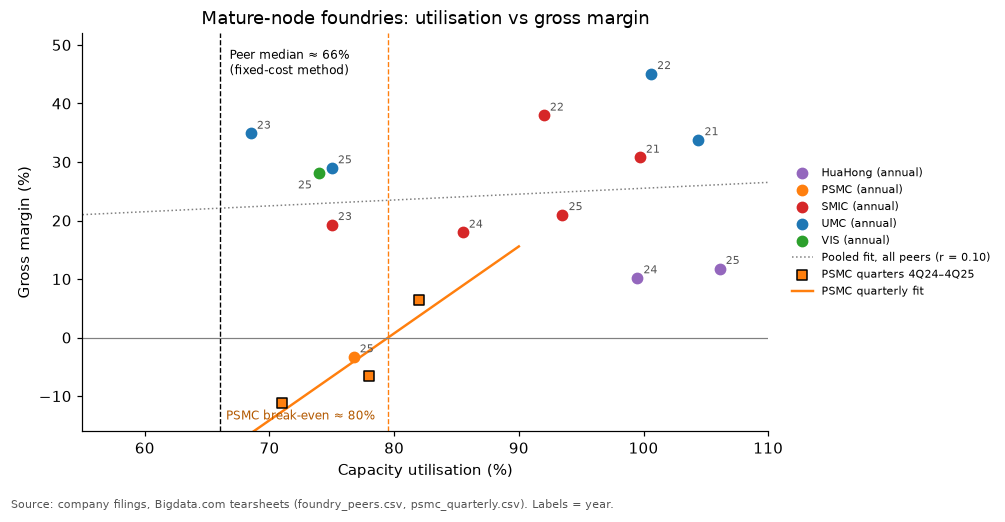

In [6]:
colors = {'UMC': '#1f77b4', 'SMIC': '#d62728', 'HuaHong': '#9467bd', 'VIS': '#2ca02c', 'PSMC': '#ff7f0e'}
fig, ax = plt.subplots(figsize=(9.2, 4.7))
for c, g in fit.groupby('company'):
    ax.scatter(g['utilisation_pct'], g['gross_margin_pct'], s=45, color=colors.get(c, 'grey'), label=f'{c} (annual)', zorder=3)
    for _, row in g.iterrows():
        off = (-14, -10) if (c == 'VIS' and row['year'] == 2025) else (4, 3)
        ax.annotate(str(row['year'])[2:], (row['utilisation_pct'], row['gross_margin_pct']), textcoords='offset points',
                    xytext=off, fontsize=7, color='#555')
xs = np.linspace(55, 110, 50)
ax.plot(xs, a + b * xs, color='grey', lw=1, ls=':', label=f'Pooled fit, all peers (r = {r:.2f})')
ax.scatter(pfit['utilisation_pct'], pfit['gross_margin_pct'], marker='s', s=40, color='#ff7f0e', edgecolor='black', zorder=4,
           label='PSMC quarters 4Q24–4Q25')
xs2 = np.linspace(65, 90, 20)
ax.plot(xs2, pa + pb * xs2, color='#ff7f0e', lw=1.6, label='PSMC quarterly fit')
ax.axhline(0, color='grey', lw=0.8)
ax.axvline(BE_NEW, color='#ff7f0e', ls='--', lw=0.9)
ax.text(BE_NEW - 13, -14, f'PSMC break-even ≈ {BE_NEW:.0f}%', fontsize=8, color='#b35900')
ax.axvline(BE_MED, color='black', ls='--', lw=0.9)
ax.text(BE_MED + 0.8, 45, f'Peer median ≈ {BE_MED:.0f}%\n(fixed-cost method)', fontsize=8)
ax.set_xlim(55, 110); ax.set_ylim(-16, 52)
ax.set_xlabel('Capacity utilisation (%)'); ax.set_ylabel('Gross margin (%)')
ax.set_title('Mature-node foundries: utilisation vs gross margin')
ax.legend(fontsize=7, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.text(0.01, 0.005, 'Source: company filings, Bigdata.com tearsheets (foundry_peers.csv, psmc_quarterly.csv). Labels = year.', fontsize=7, color='#555')
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.savefig('../charts/chart1_peers_util_gm.png', dpi=200); plt.show()

**Reading this:** there is no single break-even utilisation for "a mature-node foundry".

- **Old, depreciated fabs** (UMC, VIS) cover their cost of sales at under half capacity.
- **Fabs still carrying new-fab depreciation** (PSMC, Hua Hong) need around 80–90%. PSMC's own quarters show this directly: it lost money at 71–78% utilisation and turned positive only at 82%. Near break-even, each extra 10 points of loading was worth about 15 points of margin.
- **The peer median** is printed above. I use it as *the rough break-even utilisation for a mature-node foundry*.

**What this means for Dholera:** a brand-new fab belongs in the high-break-even group, at around 80%. It carries a full depreciation charge from day one. The subsidy changes this. Under the net method (Phase 3), ~65% capital support cuts the depreciable base by two-thirds, which pulls Dholera's break-even down towards the old-fab group. So the subsidy is not just a cash gift: it lowers the loading Tata needs to reach before the fab stops burning cash at gross-margin level.

## B. Dholera ramp and illustrative output value (Monte Carlo)

**Model, per year:**
- wafers out = 50,000 × 12 × utilisation × yield
- illustrative output value = wafers out × price per wafer

**Inputs (`dholera_inputs.csv`):**
- **Utilisation:** share of the 50k wspm design capacity, so it covers both tools installed and loading.
  - 2030: reuses the agreed Phase 2 range (10–50%).
  - 2032: anchored on the peer data. Mode = lowest peer utilisation (a downturn year); high = median peer utilisation.
- **Yield:** an assumption, because no peer discloses line yield.
- **Price:** min / median / max of peer revenue per wafer over 2021–25. This range covers the 2021–22 boom and the 2023–24 slump, so it is not anchored on 2026's tight-market prices.

10,000 draws per year from triangular distributions, `rng = np.random.default_rng(42)`. Inputs are drawn independently (see the note after the results).

In [7]:
inp = pd.read_csv('../data/dholera_inputs.csv')
CAP_YR = 50000 * 12
U_MIN = fit['utilisation_pct'].min() / 100
U_MED = fit['utilisation_pct'].median() / 100
print(f'Peer utilisation: min {U_MIN:.1%}, median {U_MED:.1%}  -> used for 2032 mode and high')

def rng_row(name, year):
    r = inp[(inp['input'] == name) & (inp['year'].astype(str) == str(year))].iloc[0]
    sub = {'peer_min': U_MIN, 'peer_median': U_MED}
    return [float(sub.get(v, v)) for v in (r['low'], r['mode'], r['high'])]

PRICE = [P_MIN, P_MED, P_MAX]
YEARS = [2028, 2029, 2030, 2031, 2032]
ranges = pd.DataFrame({y: rng_row('utilisation', y) + rng_row('yield', y) for y in YEARS},
                      index=['util_low', 'util_mode', 'util_high', 'yield_low', 'yield_mode', 'yield_high']).T
print('Price per wafer (US$):', [round(p) for p in PRICE])
ranges.round(3)

Peer utilisation: min 68.5%, median 92.0%  -> used for 2032 mode and high
Price per wafer (US$): [992, 2208, 3343]


,util_low,util_mode,util_high,yield_low,yield_mode,yield_high
2028,0.02,0.050,0.10,0.60,0.75,0.85
2029,0.08,0.180,0.30,0.75,0.85,0.92
2030,0.10,0.250,0.50,0.85,0.90,0.95
2031,0.25,0.450,0.70,0.88,0.93,0.97
2032,0.40,0.685,0.92,0.90,0.95,0.98


In [8]:
N = 10_000
rng = np.random.default_rng(42)
sims = {}
for y in YEARS:
    u = rng.triangular(*rng_row('utilisation', y), N)
    yl = rng.triangular(*rng_row('yield', y), N)
    p = rng.triangular(*PRICE, N)
    wafers = CAP_YR * u * yl
    sims[y] = pd.DataFrame({'util': u, 'yield': yl, 'price': p, 'wafers_k': wafers / 1e3, 'value_usd_m': wafers * p / 1e6})

rows = []
for y in YEARS:
    s = sims[y]
    for q, lab in [(10, 'P10'), (50, 'P50'), (90, 'P90')]:
        rows.append({'year': y, 'percentile': lab, 'wafers_out_k': round(np.percentile(s['wafers_k'], q)),
                     'illustrative_value_usd_m': round(np.percentile(s['value_usd_m'], q)),
                     'illustrative_value_rs_cr_at95': round(np.percentile(s['value_usd_m'], q) * 1e6 * 95 / 1e7)})
mc = pd.DataFrame(rows)
mc.pivot(index='year', columns='percentile', values=['wafers_out_k', 'illustrative_value_usd_m'])

wafers_out_k           illustrative_value_usd_m           
percentile          P10  P50  P90                      P10  P50   P90
year                                                                 
2028                 15   24   35                       30   52    83
2029                 64   93  126                      122  198   300
2030                 96  149  216                      186  319   504
2031                191  257  330                      355  552   792
2032                295  380  459                      539  812  1131

In [9]:
full_value = CAP_YR * 0.95 * P_MED / 1e6
print(f'Reference: full capacity at 95% yield and median price = {CAP_YR*0.95/1e3:.0f}k wafers, US${full_value:,.0f}M a year')
for y in [2030, 2032]:
    u = sims[y]['util'] * 100
    print(f'{y}: runs below peer-median break-even ({BE_MED:.0f}%): {(u < BE_MED).mean():.0%} | '
          f'below new-fab break-even ({BE_NEW:.0f}%): {(u < BE_NEW).mean():.0%}')

Reference: full capacity at 95% yield and median price = 570k wafers, US$1,259M a year
2030: runs below peer-median break-even (66%): 100% | below new-fab break-even (80%): 100%
2032: runs below peer-median break-even (66%): 45% | below new-fab break-even (80%): 87%


**Reading this:**
- **2030:** the middle case has Dholera producing about a quarter of its capacity. Its illustrative output value is a few hundred million dollars, well below the ~US$1.25 billion a year it would produce at full capacity.
- **2032:** output rises a lot, but the middle case is still around two-thirds loaded.
- **Break-even, 2030:** the printed "100% below" is true by construction, since the 2030 range tops out at 50%, below every peer break-even. It is also not a like-for-like comparison. My utilisation is measured against the 50,000 wspm *design* capacity, while peer break-evens are measured against *installed* capacity. Dholera will add tools in phases, so the tools it has could be well loaded. The real reason for 2030 losses is different. The building, cleanroom and utilities are built for the full fab and depreciated from day one, so fixed cost per wafer stays high while output is low.
- **Break-even, 2032:** assuming the fab is fully tooled by 2032, about half the runs are still below the peer median and most are below the new-fab level.

So on any reasonable view, Dholera makes gross-margin losses in 2030, before any interest or overheads. The subsidy (about 65% of project cost in present-value terms, Phase 3) is what makes these years survivable. Phase 7 will model installed capacity and loading separately to put a number on this.

**Why the independent draws matter:** in real life, a downturn lowers both price and loading at the same time. Drawing the inputs independently narrows the range, as we saw in Phase 5, so the true P10–P90 band is wider than shown here.

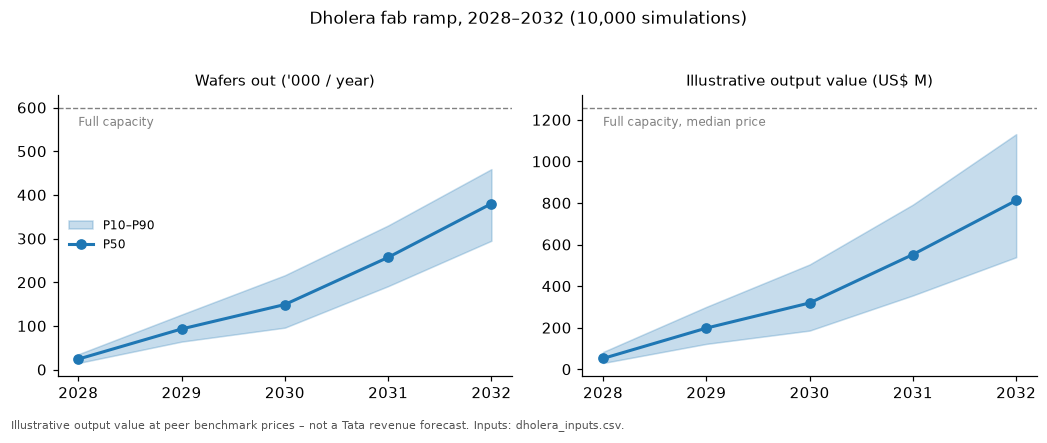

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.9))
w = mc.pivot(index='year', columns='percentile', values='wafers_out_k')
v = mc.pivot(index='year', columns='percentile', values='illustrative_value_usd_m')
for ax, d, lab, cap in [(axes[0], w, "Wafers out ('000 / year)", CAP_YR / 1e3), (axes[1], v, 'Illustrative output value (US$ M)', full_value)]:
    ax.fill_between(d.index, d['P10'], d['P90'], color='#1f77b4', alpha=0.25, label='P10–P90')
    ax.plot(d.index, d['P50'], color='#1f77b4', lw=2, marker='o', label='P50')
    ax.axhline(cap, color='grey', ls='--', lw=0.9)
    ax.text(2028, cap * 0.93, 'Full capacity' if 'Wafers' in lab else 'Full capacity, median price', fontsize=8, color='grey')
    ax.set_title(lab, fontsize=10); ax.set_xticks(YEARS)
axes[0].legend(fontsize=8, frameon=False, loc='center left')
fig.suptitle('Dholera fab ramp, 2028–2032 (10,000 simulations)', fontsize=11)
fig.text(0.01, 0.005, 'Illustrative output value at peer benchmark prices – not a Tata revenue forecast. Inputs: dholera_inputs.csv.', fontsize=7, color='#555')
plt.tight_layout(rect=[0, 0.03, 1, 0.95]); plt.savefig('../charts/chart2_dholera_ramp_mc.png', dpi=200); plt.show()

### Tornado chart for 2030

I set each input in turn to its low and its high, keeping the others at their mode. The input with the widest bar moves the 2030 value the most.

Base 2030 value (all modes): US$298M


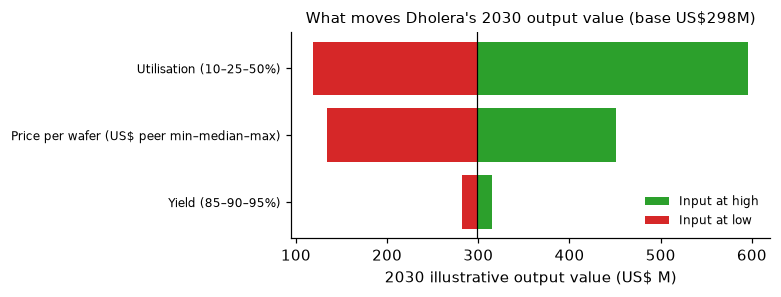

,input,low_case_usd_m,high_case_usd_m,swing
2,Yield (85–90–95%),282,315,33
1,Price per wafer (US$ peer min–median–max),134,451,317
0,Utilisation (10–25–50%),119,596,477


In [11]:
mode = {'util': rng_row('utilisation', 2030)[1], 'yield': rng_row('yield', 2030)[1], 'price': P_MED}
lims = {'Utilisation (10–25–50%)': ('util', rng_row('utilisation', 2030)),
        'Price per wafer (US$ peer min–median–max)': ('price', PRICE),
        'Yield (85–90–95%)': ('yield', rng_row('yield', 2030))}
val = lambda d: CAP_YR * d['util'] * d['yield'] * d['price'] / 1e6
base = val(mode)
tor = []
for lab, (k, (lo, _, hi)) in lims.items():
    tor.append({'input': lab, 'low_case_usd_m': round(val({**mode, k: lo})), 'high_case_usd_m': round(val({**mode, k: hi}))})
tor = pd.DataFrame(tor)
tor['swing'] = tor['high_case_usd_m'] - tor['low_case_usd_m']
tor = tor.sort_values('swing')
print(f'Base 2030 value (all modes): US${base:,.0f}M')

fig, ax = plt.subplots(figsize=(7.2, 2.8))
yy = np.arange(len(tor))
ax.barh(yy, tor['high_case_usd_m'] - base, left=base, color='#2ca02c', label='Input at high')
ax.barh(yy, tor['low_case_usd_m'] - base, left=base, color='#d62728', label='Input at low')
ax.axvline(base, color='black', lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels(tor['input'], fontsize=8)
ax.set_xlabel('2030 illustrative output value (US$ M)')
ax.set_title(f'What moves Dholera\'s 2030 output value (base US${base:,.0f}M)', fontsize=10)
ax.legend(fontsize=8, frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('../charts/chart3_tornado_2030.png', dpi=200); plt.show()
tor

**Reading this:** utilisation dominates. Whether Tata finds enough customers to load the fab matters far more than wafer price or yield. Price comes second, because the peer range is wide (Hua Hong to GlobalFoundries). Yield matters least by 2030, though it dominates in 2028–29.

## C. Demand fit: can India's market fill Dholera?

**Step 1. India's market** (Phase 2):
- US$96B in 2030 (base), with a range of US$80–119B.
- Extended to 2032 at the same 13% a year.

**Step 2. Addressable share (assumption):** the part a 28–110 nm fab could make, meaning mature logic, analog/power, MCUs and discretes.
- In WSTS 2025 data (Phase 1), memory was 29% of world chip sales and logic 38%. The remaining 33% is analog, discretes, micro, opto and sensors.
- Some mature logic, such as display drivers, adds to this. Opto, sensors and 8-inch-only products subtract.
- India's demand is handset-heavy (IESA), which pushes the memory and advanced-logic share up.
- So I use **30%** (range 25–35%). This is an assumption, not a measured figure. No source splits India's demand by node.

**Step 3.** Compare Dholera's P10/P50/P90 output value with that addressable pool.

In [12]:
MKT = {2030: {'Conservative': 80.0, 'Base': 96.0, 'Optimistic': 119.0}}
MKT[2032] = {k: round(v * (1.13 ** 2), 1) for k, v in MKT[2030].items()}
ADDR = {'low': 0.25, 'base': 0.30, 'high': 0.35}
rows = []
for y in [2030, 2032]:
    addr_base = MKT[y]['Base'] * ADDR['base']
    for lab in ['P10', 'P50', 'P90']:
        val_b = mc[(mc.year == y) & (mc.percentile == lab)]['illustrative_value_usd_m'].iloc[0] / 1000
        rows.append({'year': y, 'dholera': lab, 'dholera_value_usd_b': round(val_b, 2),
                     'india_market_base_usd_b': MKT[y]['Base'], 'addressable_usd_b (30%)': round(addr_base, 1),
                     'share_of_addressable_%': round(100 * val_b / addr_base, 1),
                     'range_%_(25-35%, cons-opt mkt)': f"{100*val_b/(MKT[y]['Optimistic']*ADDR['high']):.1f}–{100*val_b/(MKT[y]['Conservative']*ADDR['low']):.1f}"})
fitdf = pd.DataFrame(rows)
print(f'Full capacity at median price = US${full_value/1000:.2f}B = {100*full_value/1000/(96*0.30):.1f}% of 2030 base addressable pool')
fitdf

Full capacity at median price = US$1.26B = 4.4% of 2030 base addressable pool


,year,dholera,dholera_value_usd_b,india_market_base_usd_b,addressable_usd_b (30%),share_of_addressable_%,"range_%_(25-35%, cons-opt mkt)"
0,2030,P10,0.19,96.0,28.8,0.6,0.4–0.9
1,2030,P50,0.32,96.0,28.8,1.1,0.8–1.6
2,2030,P90,0.50,96.0,28.8,1.8,1.2–2.5
3,2032,P10,0.54,122.6,36.8,1.5,1.0–2.1
4,2032,P50,0.81,122.6,36.8,2.2,1.5–3.2
5,2032,P90,1.13,122.6,36.8,3.1,2.1–4.4


In [13]:
seg = pd.DataFrame([
    ['Handsets (56% of 2030 demand)', 'PMICs, display drivers (DDIC)', 'Medium', 'Chips chosen by Qualcomm/MediaTek/Samsung, not by Indian assemblers'],
    ['IT hardware / data centres (12%)', 'PMICs, power MOSFETs', 'Medium–High', 'AI-server power demand is lifting 55nm+ BCD and power prices (TrendForce 2026)'],
    ['Industrial (9%)', 'MCUs, PMICs, power discretes', 'High', 'Long product life suits a new fab once qualified'],
    ['Automotive (8%)', 'MCUs, power MOSFETs, PMICs', 'High (but slow)', 'Auto qualification takes 2–3 years; Nexperia MOSFETs and Bosch MoU point here'],
    ['Telecom, consumer, others (~15%)', 'DDIC (TVs), MCUs, mixed-signal', 'Medium', 'Price-sensitive; Chinese foundries strongest here'],
], columns=['Phase 2 segment (IESA 2030 share)', 'Dholera product types', 'Fit', 'Note'])
seg

,Phase 2 segment (IESA 2030 share),Dholera product types,Fit,Note
0,Handsets (56% of 2030 demand),"PMICs, display drivers (DDIC)",Medium,"Chips chosen by Qualcomm/MediaTek/Samsung, not..."
1,IT hardware / data centres (12%),"PMICs, power MOSFETs",Medium–High,AI-server power demand is lifting 55nm+ BCD an...
2,Industrial (9%),"MCUs, PMICs, power discretes",High,Long product life suits a new fab once qualified
3,Automotive (8%),"MCUs, power MOSFETs, PMICs",High (but slow),Auto qualification takes 2–3 years; Nexperia M...
4,"Telecom, consumer, others (~15%)","DDIC (TVs), MCUs, mixed-signal",Medium,Price-sensitive; Chinese foundries strongest here


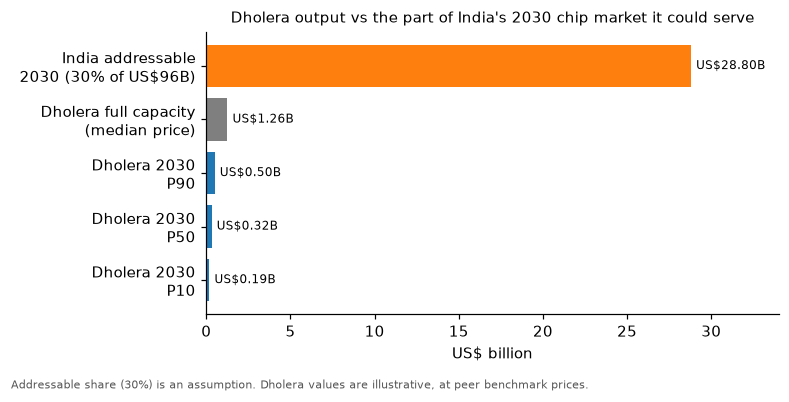

In [14]:
fig, ax = plt.subplots(figsize=(7.2, 3.6))
labels = ['India addressable\n2030 (30% of US$96B)', 'Dholera full capacity\n(median price)', 'Dholera 2030\nP90', 'Dholera 2030\nP50', 'Dholera 2030\nP10']
vals = [96 * 0.30, full_value / 1000] + [mc[(mc.year == 2030) & (mc.percentile == p)]['illustrative_value_usd_m'].iloc[0] / 1000 for p in ['P90', 'P50', 'P10']]
bars = ax.barh(labels[::-1], vals[::-1], color=['#1f77b4'] * 3 + ['#7f7f7f', '#ff7f0e'])
for bar_, v_ in zip(bars, vals[::-1]):
    ax.text(bar_.get_width() + 0.3, bar_.get_y() + bar_.get_height() / 2, f'US${v_:.2f}B', va='center', fontsize=8)
ax.set_xlabel('US$ billion'); ax.set_xlim(0, 34)
ax.set_title('Dholera output vs the part of India\'s 2030 chip market it could serve', fontsize=10)
fig.text(0.01, 0.005, 'Addressable share (30%) is an assumption. Dholera values are illustrative, at peer benchmark prices.', fontsize=7, color='#555')
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.savefig('../charts/chart4_demand_fit.png', dpi=200); plt.show()

**Reading this:** India's demand is not too small for Dholera. Even at full capacity the fab would make only about 4% of the mature-node chips India is likely to use in 2030, and only about 1% in the middle ramp case.

The real problem is who decides. Most chips consumed in India are chosen by global chip companies (Qualcomm, MediaTek, TI, Infineon, NXP), not by the Indian factories that assemble phones and cars. Tata has to win those companies as foundry customers and pass their qualification. That takes years, especially for automotive parts. Partners like Nexperia, Bosch, ROHM, Himax and Analog Devices matter more than the size of Indian demand.

If Indian-designed chips stay small (DLI approved only 24 designs, Phase 4), Dholera has to export. It will then compete directly with Chinese mature-node fabs, which are doing about 70% of the world's 12-inch mature-node expansion (TrendForce, May 2026).

## D. Outputs for the Excel workbook

In [15]:
scen = []
for y in YEARS:
    u, yl = rng_row('utilisation', y), rng_row('yield', y)
    for i, lab in enumerate(['Conservative', 'Base', 'Optimistic']):
        wafers = CAP_YR * u[i] * yl[i]
        scen.append({'scenario': lab, 'year': y, 'utilisation_%': round(100 * u[i], 1), 'yield_%': round(100 * yl[i], 1),
                     'wafers_out_k': round(wafers / 1e3), 'price_usd_per_wafer': round(PRICE[i]),
                     'illustrative_value_usd_m': round(wafers * PRICE[i] / 1e6), 'illustrative_value_rs_cr_at95': round(wafers * PRICE[i] * 95 / 1e7)})
scen = pd.DataFrame(scen).sort_values(['scenario', 'year'])
mc_out = mc.copy(); mc_out.insert(0, 'scenario', 'MonteCarlo_' + mc_out['percentile']); mc_out = mc_out.drop(columns='percentile')
scen.to_csv('../data/dholera_scenarios_2028_2032.csv', index=False)
mc_out.to_csv('../data/dholera_montecarlo_summary.csv', index=False)
tor.to_csv('../data/dholera_tornado_2030.csv', index=False)
fitdf.to_csv('../data/dholera_demand_fit.csv', index=False)
peers.to_csv('../data/foundry_peers_with_ratios.csv', index=False)
print('Saved. Hand-built scenarios move every input low (or high) together, so they are wider than the Monte Carlo band.')
scen

Saved. Hand-built scenarios move every input low (or high) together, so they are wider than the Monte Carlo band.


,scenario,year,utilisation_%,yield_%,wafers_out_k,price_usd_per_wafer,illustrative_value_usd_m,illustrative_value_rs_cr_at95
1,Base,2028,5.0,75.0,22,2208,50,472
4,Base,2029,18.0,85.0,92,2208,203,1926
7,Base,2030,25.0,90.0,135,2208,298,2832
10,Base,2031,45.0,93.0,251,2208,555,5268
13,Base,2032,68.5,95.0,390,2208,862,8192
0,Conservative,2028,2.0,60.0,7,992,7,68
3,Conservative,2029,8.0,75.0,36,992,36,339
6,Conservative,2030,10.0,85.0,51,992,51,481
9,Conservative,2031,25.0,88.0,132,992,131,1244
12,Conservative,2032,40.0,90.0,216,992,214,2036


**Limitations**
- **Peer data:** 2019–20 is missing and GF has no utilisation data. The pooled utilisation–margin fit is flat (r ≈ 0.1). The break-even numbers rest on one disclosed fixed-cost share (UMC) and three PSMC quarters, so treat them as rough guides.
- **Prices:** peer revenue per wafer mixes nodes and products, and GF and PSMC revenue includes some non-wafer income. A new entrant may also have to price below peers to win customers. That would pull values towards the low end.
- **Yield:** yield is an assumption, because no peer discloses it.
- **Independent draws:** a real downturn hits price and loading together, so the true range is wider than the Monte Carlo band.
- **Not Tata's revenue:** nothing here is Tata's revenue or profit. Tata Semiconductor Manufacturing had no turnover in FY26 (Tata Sons annual report, AOC-1).